In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
file_path = "/kaggle/input/datasets/samuelsemaya/e-commerce-customer-churn/data_ecommerce_customer_churn.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (3941, 11)


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


In [3]:
target_column = 'Churn' if 'Churn' in df.columns else df.columns[-1]

X = df.drop(columns=[target_column])
Y = df[target_column]

# Convert target to binary values if needed
if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().str.lower()

    Y = Y.map({
        'yes': 1,
        'no': 0,
        'true': 1,
        'false': 0,
        '1': 1,
        '0': 0
    })

# Remove rows with missing target values
valid_rows = Y.notna()

X = X.loc[valid_rows]
Y = Y.loc[valid_rows].astype(int)

# Select numeric features
X = X.select_dtypes(include=np.number)

print("Features Shape:", X.shape)
print("Target Distribution:")
print(Y.value_counts())

Features Shape: (3941, 8)
Target Distribution:
Churn
0    3267
1     674
Name: count, dtype: int64


In [4]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (3152, 8)
Testing Shape: (789, 8)


In [5]:
# Handle missing values
imputer = SimpleImputer(strategy='mean')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Add bias column
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

Y_train = np.array(Y_train)
Y_test = np.array(Y_test)

print("Preprocessing Completed!")
print("X_train_bias:", X_train_bias.shape)
print("X_test_bias:", X_test_bias.shape)

Preprocessing Completed!
X_train_bias: (3152, 9)
X_test_bias: (789, 9)


In [7]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [8]:
def binary_cross_entropy(Y, probabilities):
    epsilon = 1e-8

    probabilities = np.clip(
        probabilities,
        epsilon,
        1 - epsilon
    )

    loss = -np.mean(
        Y * np.log(probabilities) +
        (1 - Y) * np.log(1 - probabilities)
    )

    return loss

In [9]:
def logistic_mini_batch(
    X,
    Y,
    learning_rate=0.05,
    batch_size=64,
    epochs=100
):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)

    losses = []

    for epoch in range(epochs):

        # Shuffle training data
        indices = np.random.permutation(n_samples)

        X_shuffled = X[indices]
        Y_shuffled = Y[indices]

        # Divide data into mini-batches
        for start in range(0, n_samples, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            Y_batch = Y_shuffled[start:end]

            # Forward propagation
            predictions = sigmoid(
                np.dot(X_batch, weights)
            )

            # Calculate gradient
            gradient = np.dot(
                X_batch.T,
                (predictions - Y_batch)
            ) / len(Y_batch)

            # Update weights
            weights -= learning_rate * gradient

        # Calculate loss after each epoch
        train_probabilities = sigmoid(
            np.dot(X, weights)
        )

        epoch_loss = binary_cross_entropy(
            Y,
            train_probabilities
        )

        losses.append(epoch_loss)

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {epoch_loss:.4f}"
        )

    return weights, losses

In [10]:
weights_minibatch, losses_minibatch = logistic_mini_batch(
    X_train_bias,
    Y_train,
    learning_rate=0.05,
    batch_size=64,
    epochs=100
)

print("Mini-Batch Gradient Descent Training Completed!")

Epoch 1/100, Loss: 0.4866
Epoch 2/100, Loss: 0.4156
Epoch 3/100, Loss: 0.3838
Epoch 4/100, Loss: 0.3659
Epoch 5/100, Loss: 0.3551
Epoch 6/100, Loss: 0.3479
Epoch 7/100, Loss: 0.3429
Epoch 8/100, Loss: 0.3393
Epoch 9/100, Loss: 0.3366
Epoch 10/100, Loss: 0.3345
Epoch 11/100, Loss: 0.3328
Epoch 12/100, Loss: 0.3315
Epoch 13/100, Loss: 0.3304
Epoch 14/100, Loss: 0.3295
Epoch 15/100, Loss: 0.3288
Epoch 16/100, Loss: 0.3282
Epoch 17/100, Loss: 0.3277
Epoch 18/100, Loss: 0.3273
Epoch 19/100, Loss: 0.3269
Epoch 20/100, Loss: 0.3267
Epoch 21/100, Loss: 0.3264
Epoch 22/100, Loss: 0.3261
Epoch 23/100, Loss: 0.3259
Epoch 24/100, Loss: 0.3258
Epoch 25/100, Loss: 0.3256
Epoch 26/100, Loss: 0.3255
Epoch 27/100, Loss: 0.3254
Epoch 28/100, Loss: 0.3253
Epoch 29/100, Loss: 0.3252
Epoch 30/100, Loss: 0.3251
Epoch 31/100, Loss: 0.3250
Epoch 32/100, Loss: 0.3250
Epoch 33/100, Loss: 0.3250
Epoch 34/100, Loss: 0.3249
Epoch 35/100, Loss: 0.3249
Epoch 36/100, Loss: 0.3249
Epoch 37/100, Loss: 0.3248
Epoch 38/1

In [11]:
# Predict probabilities
Y_pred_prob = sigmoid(
    np.dot(X_test_bias, weights_minibatch)
)

# Convert probabilities to binary predictions
Y_pred = (Y_pred_prob >= 0.5).astype(int)

print("Predictions Completed!")

Predictions Completed!


In [12]:
test_loss = binary_cross_entropy(
    Y_test,
    Y_pred_prob
)

accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred, zero_division=0)
recall = recall_score(Y_test, Y_pred, zero_division=0)
f1 = f1_score(Y_test, Y_pred, zero_division=0)

print("Mini-Batch Gradient Descent Evaluation")
print("--------------------------------------")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"Loss:      {test_loss:.4f}")

Mini-Batch Gradient Descent Evaluation
--------------------------------------
Accuracy:  0.8606
Precision: 0.6623
Recall:    0.3778
F1-Score:  0.4811
Loss:      0.3131


In [13]:
minibatch_results = pd.DataFrame({
    'Optimizer': ['Mini-Batch Gradient Descent'],
    'Accuracy': [accuracy],
    'Precision': [precision],
    'Recall': [recall],
    'F1-Score': [f1],
    'Loss': [test_loss]
})

minibatch_results

,Optimizer,Accuracy,Precision,Recall,F1-Score,Loss
0,Mini-Batch Gradient Descent,0.860583,0.662338,0.377778,0.481132,0.313053


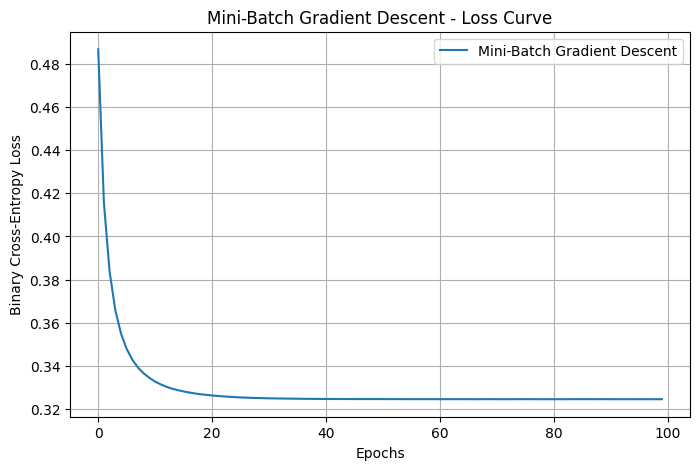

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    losses_minibatch,
    label='Mini-Batch Gradient Descent'
)

plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('Mini-Batch Gradient Descent - Loss Curve')

plt.legend()
plt.grid(True)
plt.show()

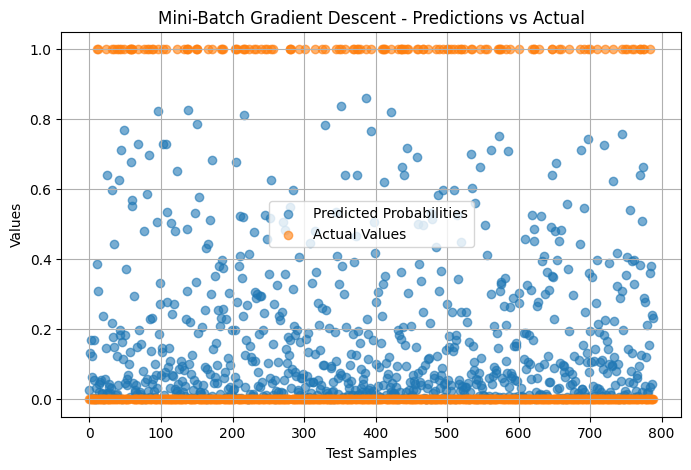

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    range(len(Y_test)),
    Y_pred_prob,
    label='Predicted Probabilities',
    alpha=0.6
)

plt.scatter(
    range(len(Y_test)),
    Y_test,
    label='Actual Values',
    alpha=0.6
)

plt.xlabel('Test Samples')
plt.ylabel('Values')
plt.title('Mini-Batch Gradient Descent - Predictions vs Actual')

plt.legend()
plt.grid(True)
plt.show()